In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

%matplotlib inline
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

rc = {
    "savefig.dpi": 400,
    "font.family": "Inter",
    "mathtext.fontset": "stixsans",
}

sns.set_theme(style='white', context='notebook', color_codes=True, rc=rc)

In [2]:
mpl.rcParams["xtick.major.width"]

1.25

In [3]:
cafe = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-09-08/cafe.csv')
cappuccino_index = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-09-08/cappuccino_index.csv')

# replace the non-breaking spaces in `country`

cafe['country'] = cafe['country'].str.replace('\u00a0', ' ')
cappuccino_index['country'] = cappuccino_index['country'].str.replace('\u00a0', ' ')

In [4]:
data = cafe[cafe.country == "Germany"].sort_values("hourly_wage").iloc[:-3]

data

,country,city,urban,suburban,rural,hourly_wage_gbp,price_gbp,original_currency,price,hourly_wage
2041,Germany,Munich,True,False,False,9.85,2.74,EUR - Euro,3.2,11.50
623,Germany,NaN,False,True,False,10.28,3.85,EUR - Euro,4.5,12.00
2230,Germany,Berlin,True,False,False,10.28,2.57,EUR - Euro,3.0,12.00
694,Germany,Cologne,True,False,False,10.63,3.77,EUR - Euro,4.4,12.41
1049,Germany,Hannover,False,True,False,10.66,3.60,EUR - Euro,4.2,12.45
...,...,...,...,...,...,...,...,...,...,...
1252,Germany,Bielefeld,True,False,False,17.99,3.43,EUR - Euro,4.0,21.00
1269,Germany,Munich,True,False,False,18.84,3.43,EUR - Euro,4.0,22.00
1399,Germany,Hamburg,True,False,False,18.84,3.34,EUR - Euro,3.9,22.00
1364,Germany,Munich,True,False,False,19.70,3.34,EUR - Euro,3.9,23.00


<Axes: xlabel='price', ylabel='hourly_wage'>

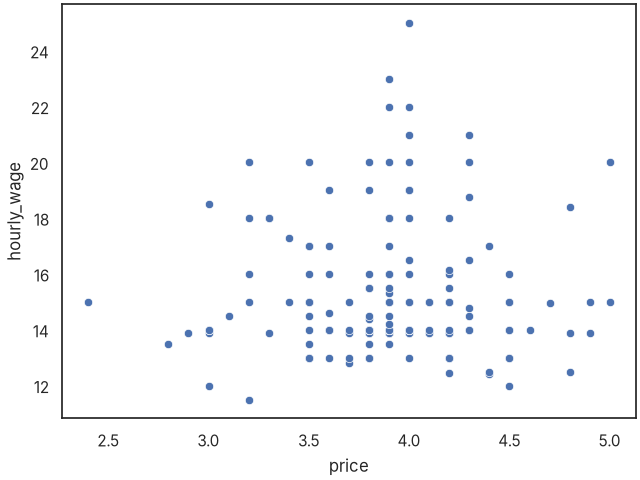

In [5]:
fig, ax = plt.subplots(layout="constrained")

sns.scatterplot(data=data, x="price", y="hourly_wage", ax=ax)

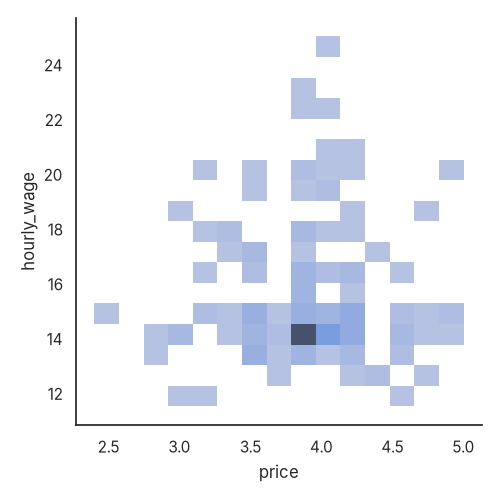

In [6]:
sns.displot(data=data, x="price", y="hourly_wage")

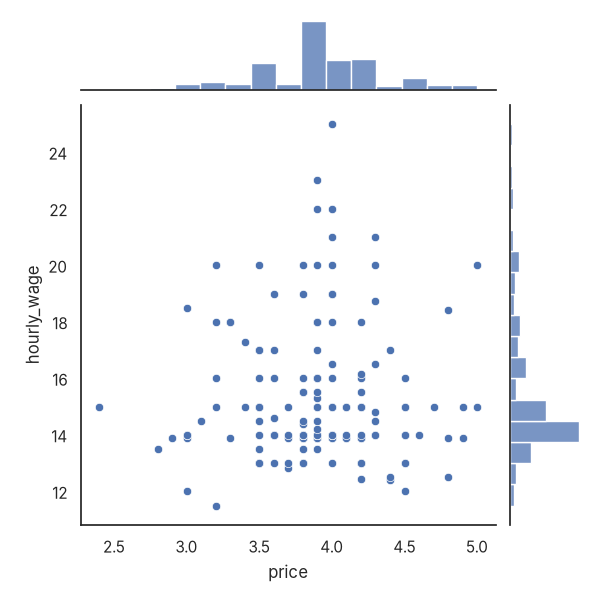

In [7]:
sns.jointplot(data=data, x="price", y="hourly_wage")

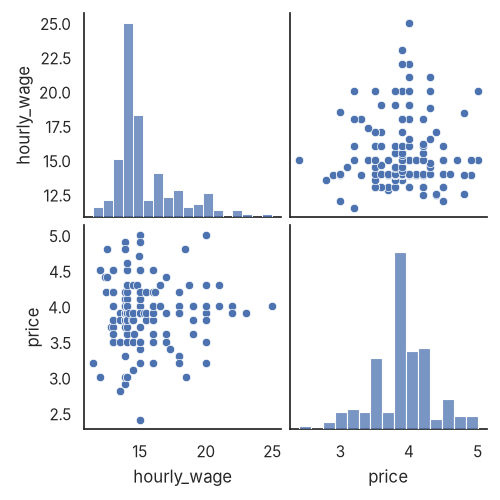

In [8]:
sns.pairplot(data[["hourly_wage", "price"]])

In [9]:
data.mean(numeric_only=True)

urban               0.853659
suburban            0.121951
rural               0.036585
hourly_wage_gbp    13.073110
price_gbp           3.339695
price               3.899390
hourly_wage        15.262134
dtype: float64

<Axes: xlabel='city', ylabel='price'>

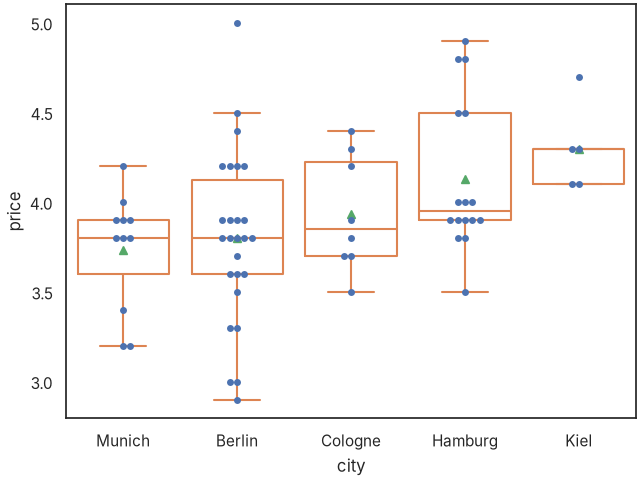

In [10]:
fig, ax = plt.subplots(layout="constrained")

sns.swarmplot(
    data=data.groupby("city").filter(lambda g: len(g) > 4),
    x="city", y="price"
)

sns.boxplot(
    data=data.groupby("city").filter(lambda g: len(g) > 4),
    x="city", y="price", fill=False, showfliers=False, showmeans=True
)

<Axes: xlabel='city', ylabel='price'>

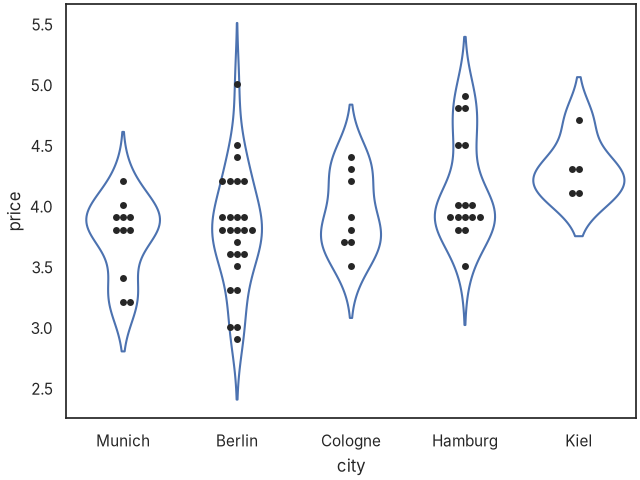

In [11]:
fig, ax = plt.subplots(layout="constrained")

sns.swarmplot(
    data=data.groupby("city").filter(lambda g: len(g) > 4),
    x="city", y="price", color=".15", ax=ax
)

sns.violinplot(
    data=data.groupby("city").filter(lambda g: len(g) > 4),
    x="city", y="price", inner=None, fill=False, ax=ax
)

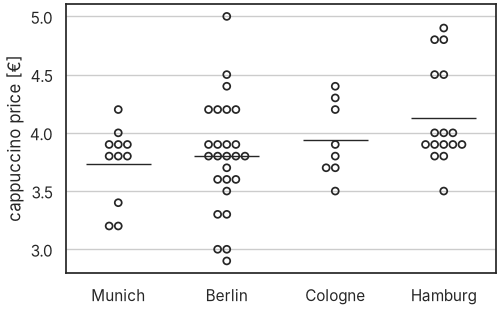

In [30]:
final = data.groupby("city").filter(lambda g: len(g) > 5)

FIGWIDTH = 5
fig, ax = plt.subplots(figsize=(FIGWIDTH, 0.618*FIGWIDTH), layout="constrained")

sns.swarmplot(
    data=final, x="city", y="price", ax=ax,
    edgecolor=".15", linewidth=1.25, facecolors="none" 
)

# sns.boxplot(
#     data=data.groupby("city").filter(lambda g: len(g) > 5),
#     x="city", y="price", color=".15", fill=False, showfliers=False, linewidth=1.25, ax=ax
# )

# add mean as horizontal line
means = final.groupby("city")["price"].mean()
for i, c in enumerate([t.get_text() for t in ax.get_xticklabels()]):  # order as plotted
    ax.hlines(means[c], i - 0.3, i + 0.3, color="0.15", linewidth=1)

ax.grid(axis="y")
ax.set_xlabel(None)
ax.set_ylabel("cappuccino price [€]")

fig.savefig("cappuccino.png")